<H1>TED</H1> 
Plot and analyze data from TED at Kane Ave.  
<hr>
<H2>Modification history </H2><br> 
<table>
    <tr>
        <th> Modified </th>
        <th> By </th>
        <th> Reason </th>
    </tr>
    <tr> 
        <td> 26-Feb-26 </td>
        <td> CBL </td> 
        <td> Original </td>
    </tr>
    <tr> 
        <td> 01-Mar-26 </td>
        <td> CBL </td> 
        <td> Make a method to form the URL for the pull. </td>
    </tr>
</table>
<hr> 
<H2> References </H2> 
References: <br> 
<a href="https://pandas.pydata.org/docs/getting_started/index.html#getting-started"> PANDAS getting started</a> <br> 

<H2> Notes </H2>
To get data via URL it looks something like this:<br> 
http://10.168.168.178/history/export.csv?M=1&D=0&C=2880&T=2&U=1772139529134 <br> 
where the fields are: 
<ul>
    <li> M channel the data is desired </li>
    <li> D Device </li>
    <ul>
        <li> 0 - MTU</li>
        <li> 1 - Shop 1</li>
        <li> 2 - AC 1 - First floor power plant. </li>
        <li> 3 - AC 2</li>
        <li> 4 - Kitchen</li>
        <li> 5 - Shop 2 but I think this is AC2 Second floor power plant</li>
    </ul>
    <li> T - time interval, </li>
    <ul>
        <li> 0 - Minute </li>
        <li> 1 - Minute </li>
        <li> 2 - Hour </li>
        <li> 3 - Day </li>
        <li> 4 - Year? </li>
    </ul>
    <li> U - Seconds since epoch </li>
    <li> C= 2880 or 1560 not sure what this is. </li> 
</ul>
M=255,T=1 export second data from MTU <br> 


In [24]:
# imports
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import requests
import time
import matplotlib.dates as mdates

In [7]:
# Test reading in, and plotting the MTU data
# This is second data. Do a pull for minute data. 
TED = pd.read_csv("Data/260226_MTU.csv")
# fields are: MTU, Time, Power, Cost, Voltage
# each URL does a pull on specific data returned in CSV format. 
#TED.plot("Time", "Power")
print(TED)

       MTU                 Time   Power   Cost   Voltage
0     MTU1  02/26/2026 14:33:36   1.413   0.26     121.4
1     MTU1  02/26/2026 14:33:35   1.407   0.26     121.1
2     MTU1  02/26/2026 14:33:34   1.405   0.25     121.1
3     MTU1  02/26/2026 14:33:33   1.415   0.26     121.4
4     MTU1  02/26/2026 14:33:32   1.408   0.26     121.1
...    ...                  ...     ...    ...       ...
3691  MTU1  02/26/2026 13:32:05   2.254   0.41     121.3
3692  MTU1  02/26/2026 13:32:04   2.232   0.40     121.1
3693  MTU1  02/26/2026 13:32:03   2.245   0.40     121.4
3694  MTU1  02/26/2026 13:32:02   2.233   0.40     121.3
3695  MTU1  02/26/2026 13:32:01   2.592   0.47     120.8

[3696 rows x 5 columns]


In [20]:
# This is 'ALL' from the MTU and includes power factor. 
# http://10.168.168.178/history/export.csv?M=1&D=0&C=2880&T=2&U=1772139529134
#
TED = pd.read_csv("Data/260226_MTU_minute.csv")

In [12]:
print(TED.index)

RangeIndex(start=0, stop=3696, step=1)


In [21]:
print(TED.columns)

Index(['MTU', ' Time', ' Power', ' Cost', ' Voltage', ' PF'], dtype='str')


Text(0, 0.5, 'kW')

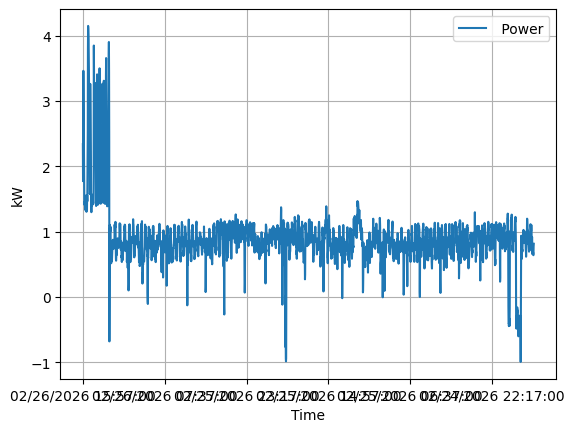

In [22]:
TED.plot(' Time', ' Power')
plt.grid()
plt.xlabel('Time')
plt.ylabel('kW')

In [19]:
print(TED[' Power'][0:20])

0     1.413
1     1.407
2     1.405
3     1.415
4     1.408
5     1.408
6     1.418
7     1.406
8     1.406
9     1.415
10    1.408
11    1.407
12    1.414
13    1.411
14    2.560
15    2.575
16    1.408
17    1.408
18    1.413
19    2.557
Name:  Power, dtype: float64


Text(0, 0.5, 'Power Factor')

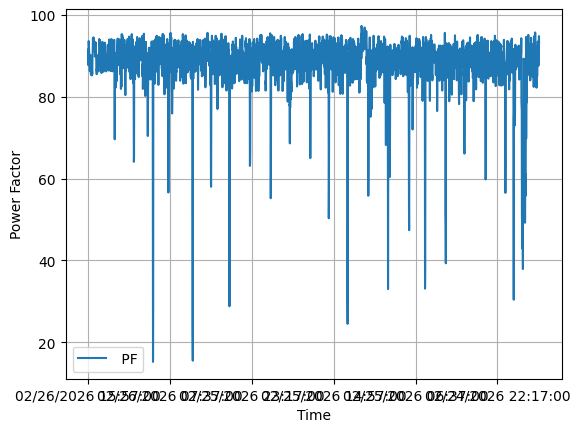

In [23]:
TED.plot(' Time', ' PF')
plt.grid()
plt.xlabel('Time')
plt.ylabel('Power Factor')

In [28]:
# lets see if we can do this directly from a URL
url = "http://10.168.168.178/history/export.csv?M=1&D=0&C=2880&T=2&U=1772143583207"
# https://stackoverflow.com/questions/32400867/pandas-read-csv-from-url
# apparently just pass the URL directly to the read. 
#s = requests.get(url).content
TED = pd.read_csv(url)
print(TED.columns)

Index(['MTU', ' Time', ' Power', ' Cost', ' Voltage', ' PF'], dtype='str')


Text(0, 0.5, 'kW')

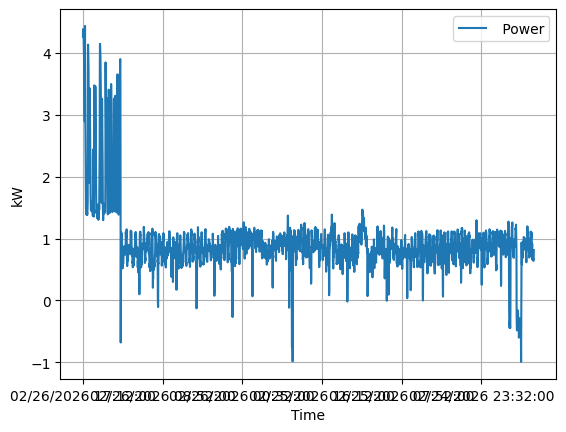

In [29]:
TED.plot(' Time', ' Power')
plt.grid()
plt.xlabel('Time')
plt.ylabel('kW')

In [11]:
def MakeRequest(MTU, Channel, Decimation):
    """
    return a URL request based on the input data. 
    MTU: boolean just MTU data. 
    Channel:
        0 - MTU
        1 - Shop 1
        2 - AC 1
        3 - AC 2 (Shop 2)
        4 - Kitchen
        5 - Shop 2 (AC 2)
        
    Decimation
        0 - Minute
        1 - Minute
        2 - Hour
        3 - Day
        4 - Year??
    """

    IP  = '10.168.168.178'
    UTC = str(time.time())
    UTC_str = UTC.replace(".","")[:13]
    
    # alternative, 
    
    if (MTU):
        # example --- http://10.168.168.178/history/export.csv?M=1&D=0&C=2880&T=2&U=1772394363642
        # when decimation is minutes, then we get the power factor. 
        url = 'http://' + IP + '/history/export.csv?M=1&D=0&C=2880&T=' + str(Decimation) + '&U='+str(UTC_str)
    else:
        # http://10.168.168.178/history/export.csv?M=1&D=1&C=1560&T=1&U=1772394586004
        url = 'http://' + IP + '/history/export.csv?M=' + str(Channel) + '&D=1&C=1560&T='+ str(Decimation) + '&U='+str(UTC_str)

    return url

In [18]:
url = MakeRequest(False, 2, 2)
print(url)

http://10.168.168.178/history/export.csv?M=2&D=1&C=1560&T=2&U=1772396174595


In [8]:
# Test code
from datetime import datetime, timezone
utc_now = datetime.now(timezone.utc)
seconds = utc_now.timestamp()
newone  = str(seconds)
val = newone.replace(".","")[:13]
print(seconds, "  ", val)

1772395857.230514    1772395857230


(0.0, 3.5)

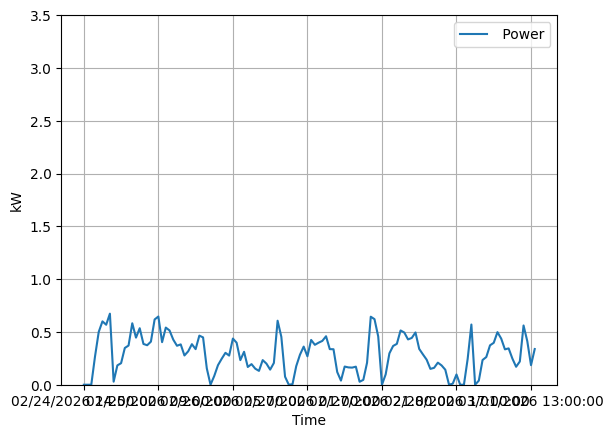

In [41]:
# Ok now solve the order problem
url = MakeRequest(False, 5, 2)
TED = pd.read_csv(url)
TED_r = TED[::-1]
# Change the date format
#
#TED[' Time'] = pd.to_datetime(TED[' Time'], format='%H:%M:%S')
#print(TED.columns)
TED_r.plot(' Time', ' Power')
plt.grid()
plt.xlabel('Time')
plt.ylabel('kW')
plt.ylim(ymin=0.0, ymax=3.5)
#formatter= mdates.DateFormatter(' %d %H:%M:%S')
#plt.gca().xaxis.set_major_formatter(formatter)